# 02 - Cleaning and EDA: NYC Citi Bike, 2013 - now

**Who worked on this:**Mohammed AbuQamar

**Input:** `citibike_data/raw/` (from `01_download`). **Output:** none. This notebook *decides* the cleaning steps and explains why. `03_prepare` then runs them on all data.

**Why a sample?** 300+ million trips do not fit in memory. A **uniform random sample of 0.5% of all trips** (~1.6M rows) is plenty for distributions, plots and statistical tests. Totals are scaled back up (x200) where we show volumes.

Every cleaning step is a function in `src/cleaning.py`. Here we call them one by one and check before/after that each one actually improves the data. 03 calls the exact same functions, so there is only one version of the cleaning.

**Plan**
1. First look and the two schemas
2. Column names
3. Types and labels
4. Duplicates
5. Missing values
6. Outliers (duration, location, speed)
7. Categoricals
8. The long-term story (2013 - now)
9. Station IDs vs station names (important for the model)
10. Aggregations
11. Testable hypotheses

**Story and purpose:**

We imagin that Citi would binefit from haveing a mudol to be able to predict the hourly demand for every sation at a certain hour so they can be prepared inase of an even or just to reduct the day to day trafic

In [1]:
import sys
sys.path.append(".")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import cleaning as cl

sns.set_theme(style="whitegrid")
SAMPLE_PCT = 0.5
SCALE = 100 / SAMPLE_PCT          # sample count x SCALE ~ real count

raw = cl.load_raw_sample(pct=SAMPLE_PCT)     # cached after the first run
raw["schema"] = np.where(raw["ride_id"].isna(), "legacy", "current")
print(raw.shape)
print(f"Memory: {raw.memory_usage(deep=True).sum() / 1e9:.1f} GB")

KeyboardInterrupt: 

## 1. First look
One example of each schema. Everything is still text, exactly as it was in the CSVs.

In [2]:
display(raw["schema"].value_counts().to_frame("rows in sample"))
display(raw[raw.schema == "legacy"].head(3))
display(raw[raw.schema == "current"].head(3))

,rows in sample
schema,
current,1183560
legacy,575200


,ride_id,rideable_type,started_at,ended_at,start_station_id,start_station_name,start_lat,start_lng,end_station_id,end_station_name,end_lat,end_lng,member_casual,bike_id,trip_duration,birth_year,gender,source_file,schema
0,NaN,NaN,2013-06-01 01:48:50,2013-06-01 02:02:29,402,Broadway & E 22 St,40.7403432,-73.98955109,401,Allen St & Rivington St,40.72019576,-73.98997825,Subscriber,16059,819,1965,1,201306-citibike-tripdata.csv,legacy
1,NaN,NaN,2013-06-01 02:32:20,2013-06-01 02:41:20,83,Atlantic Ave & Fort Greene Pl,40.68382604,-73.97632328,396,Lefferts Pl & Franklin Ave,40.680342423,-73.9557689392,Subscriber,17727,540,1981,1,201306-citibike-tripdata.csv,legacy
2,NaN,NaN,2013-06-01 03:48:24,2013-06-01 05:17:24,358,Christopher St & Greenwich St,40.73291553,-74.00711384,358,Christopher St & Greenwich St,40.73291553,-74.00711384,Customer,15937,5340,NULL,0,201306-citibike-tripdata.csv,legacy


,ride_id,rideable_type,started_at,ended_at,start_station_id,start_station_name,start_lat,start_lng,end_station_id,end_station_name,end_lat,end_lng,member_casual,bike_id,trip_duration,birth_year,gender,source_file,schema
575200,982E97099828C64C,classic_bike,2020-01-30 11:04:05.569,2020-01-30 11:06:57.845,7260.09,Amsterdam Ave & W 73 St,40.779668,-73.98093,7281.09,W 76 St & Columbus Ave,40.780184,-73.977285,member,NaN,NaN,NaN,NaN,202001-citibike-tripdata_1.csv,current
575201,DEE65D0FC08CCFA8,classic_bike,2020-01-06 08:50:08.354,2020-01-06 09:13:59.124,4677.06,Montague St & Clinton St,40.694272,-73.992327,4962.04,Water - Whitehall Plaza,40.702551,-74.012723,member,NaN,NaN,NaN,NaN,202001-citibike-tripdata_1.csv,current
575202,5DF346FA497AA16E,classic_bike,2020-01-28 08:19:15.898,2020-01-28 08:28:16.826,6004.06,E 27 St & 1 Ave,40.739445,-73.976806,6289.06,Broadway & W 29 St,40.746201,-73.988557,member,NaN,NaN,NaN,NaN,202001-citibike-tripdata_1.csv,current


## 2. Column names
01 already mapped every header to one canonical, `snake_case` name. Over the years the same column had up to three spellings, so the mapping compares names after lower-casing and removing spaces and underscores so we can get more unified name to be asier to work with:

In [3]:
aliases = pd.Series(cl._ALIASES, name="canonical").rename_axis("header (squashed)").reset_index()
display(aliases.groupby("canonical")["header (squashed)"].apply(", ".join).to_frame())

,header (squashed)
canonical,
bike_id,bikeid
birth_year,birthyear
end_lat,"endlat, endstationlatitude"
end_lng,"endlng, endstationlongitude"
end_station_id,endstationid
end_station_name,endstationname
ended_at,"endedat, stoptime"
gender,gender
member_casual,"membercasual, usertype"


*Check:* which column is filled in which year? (year taken from the raw start time)

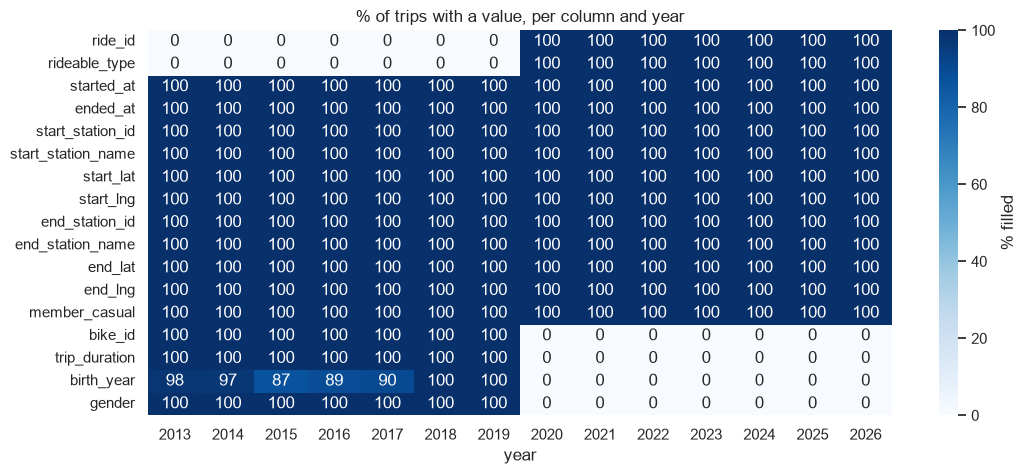

In [4]:
year = cl.parse_datetime(raw["started_at"]).dt.year
filled = raw[cl.CANONICAL].notna().groupby(year).mean().mul(100).round(0)
plt.figure(figsize=(12, 5))
sns.heatmap(filled.T, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% filled"})
plt.title("% of trips with a value, per column and year"); plt.xlabel("year"); plt.show()

The 2020 schema change is clearly visible:
- **Only before 2020:** `bike_id`, `trip_duration`, `birth_year`, `gender`. We drop them later. We recompute duration ourselves, and birth year and gender are personal data that the current data no longer has.
- **Only from 2020:** `ride_id` and `rideable_type`.

## 3. Types and labels
`cl.set_types` does four things:
- turns placeholders (`""`, `NULL`, `\N`) into real NA
- parses the timestamps, whose format changed several times (`2013-07-01 00:00:00`, `9/1/2014 00:00:04`, `1/1/2015 0:01`, `2024-01-01 00:00:00.123`)
- turns coordinates into numbers
- translates the legacy labels: `Subscriber` -> `member`, `Customer` -> `casual`; and `docked_bike` (2021-22) -> `classic_bike`, since it is the same bike

In [5]:
print("BEFORE"); display(pd.crosstab(raw["member_casual"].fillna("NA"), raw["schema"]))
display(pd.crosstab(raw["rideable_type"].fillna("NA"), raw["schema"]))

df = cl.set_types(raw)

print("AFTER"); display(pd.crosstab(df["member_casual"].fillna("NA"), df["schema"]))
display(pd.crosstab(df["rideable_type"].fillna("NA"), df["schema"]))
print("Timestamps that could not be parsed:", int(df["started_at"].isna().sum()))
print(df[["started_at", "start_lat"]].dtypes)

BEFORE


schema,current,legacy
member_casual,,
Customer,0,69313
NA,0,242
Subscriber,0,505645
casual,239186,0
member,944374,0


schema,current,legacy
rideable_type,,
NA,0,575200
classic_bike,545056,0
electric_bike,638504,0


AFTER


schema,current,legacy
member_casual,,
NA,0,242
casual,239186,69313
member,944374,505645


schema,current,legacy
rideable_type,,
NA,0,575200
classic_bike,545056,0
electric_bike,638504,0


Timestamps that could not be parsed: 0
started_at    datetime64[us]
start_lat            float64
dtype: object


## 4. Duplicates
Current data: `ride_id` must be unique. Legacy data has no id, so there a duplicate means the same bike, the same start and end time, and the same stations.

*Note:* in a random sample both copies of a duplicate are rarely picked together, so this check finds (almost) nothing here. The real numbers on all data are in the report of `03_prepare`.

In [6]:
before = len(df)
df = cl.drop_duplicates(df)
print(f"Removed {before - len(df):,} duplicates in the sample")

Removed 532 duplicates in the sample


## 5. Missing values
First *where* are they, and are they random?

In [7]:
na = df[cl.CANONICAL].isna().groupby(df["schema"]).mean().mul(100).round(2).T
display(na[(na > 0).any(axis=1)])

cur = df[df.schema == "current"]
display(cur.assign(no_end_station=cur["end_station_name"].isna())
           .groupby("rideable_type")["no_end_station"].mean().mul(100).round(2)
           .to_frame("% trips without end station"))

schema,current,legacy
ride_id,0.00,100.00
rideable_type,0.00,100.00
start_station_id,0.04,0.01
start_station_name,0.04,0.01
start_lat,0.04,0.00
start_lng,0.04,0.00
end_station_id,0.28,0.04
end_station_name,0.26,0.04
end_lat,0.25,0.03
end_lng,0.25,0.03


,% trips without end station
rideable_type,
classic_bike,0.17
electric_bike,0.34


**Decision** (`cl.handle_missing`):
- **Missing station names/ids:** mostly effects on e-bikes, which can be locked outside a dock. That is a structural NA, so we fill it with `"no_station"` instead of dropping these trips.
- **Missing `rideable_type`:** not recorded before 2021, so we fill it with `"unknown"`.
- **Missing `member_casual`:** filled with `"unknown"` (very rare).
- **Missing timestamps or coordinates:** we cannot compute duration or distance, so we drop the row.

*Check:* afterwards none of the columns we need may contain NA.

In [8]:
before = len(df)
df = cl.handle_missing(df)
print(f"Dropped {before - len(df):,} rows ({(before - len(df)) / before:.3%})")
need = ["started_at", "ended_at", *cl.STATION_COLS, *cl.COORD_COLS, "rideable_type", "member_casual"]
print("NAs left in needed columns:", int(df[need].isna().sum().sum()))

Dropped 3,381 rows (0.192%)
NAs left in needed columns: 0


## 6. Outliers
`cl.add_trip_metrics` computes `duration_min`, the straight-line `distance_km` (haversine) and `speed_kmh`.
### 6a. Duration
Negative or zero durations are impossible. Rides under 1 minute are false starts or re-docks. Rides over 24 hours are lost, stolen or never-docked bikes.

,before
count,1754847.0
mean,16.9
std,669.3
min,-52.8
0.1%,1.1
1%,1.5
50%,9.9
99%,64.9
99.9%,270.6
max,560666.2


<= 0 min: 7 | < 1 min: 10 | > 24 h: 278


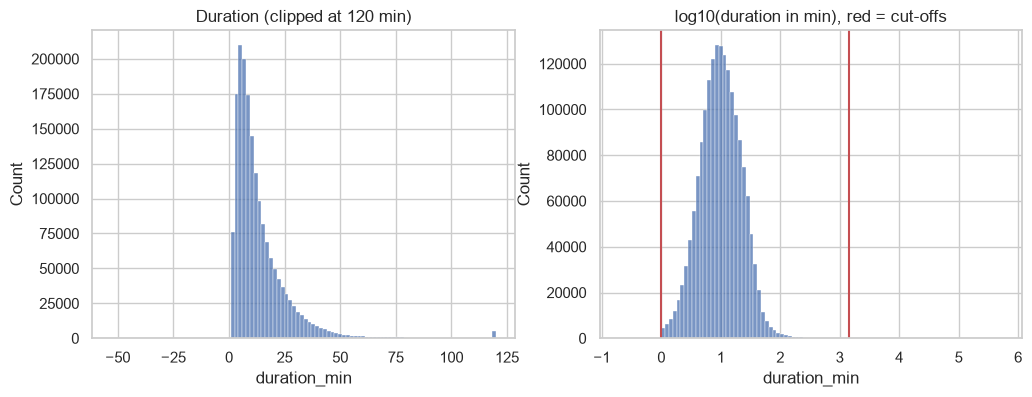

In [9]:
df = cl.add_trip_metrics(df)
display(df["duration_min"].describe(percentiles=[.001, .01, .5, .99, .999]).round(1).to_frame("before"))
print("<= 0 min:", (df.duration_min <= 0).sum(), "| < 1 min:", (df.duration_min < 1).sum(),
      "| > 24 h:", (df.duration_min > 24 * 60).sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["duration_min"].clip(upper=120), bins=100, ax=ax[0])
ax[0].set_title("Duration (clipped at 120 min)")
sns.histplot(np.log10(df.loc[df.duration_min > 0, "duration_min"]), bins=100, ax=ax[1])
ax[1].axvline(np.log10(cl.MIN_DURATION_MIN), color="r"); ax[1].axvline(np.log10(cl.MAX_DURATION_MIN), color="r")
ax[1].set_title("log10(duration in min), red = cut-offs")
plt.show()

In [10]:
before = len(df)
df = cl.filter_duration(df)
print(f"Removed {before - len(df):,} rows ({(before - len(df)) / before:.2%})")
display(df["duration_min"].describe(percentiles=[.01, .5, .99]).round(1).to_frame("after"))

Removed 288 rows (0.02%)


,after
count,1754559.0
mean,14.2
std,24.5
min,1.0
1%,1.5
50%,9.9
99%,64.5
max,1438.5


### 6b. Location
Points at `0,0` or far outside the city are GPS or test-bike errors. The box includes Jersey City and Hoboken, because some trips cross the river.

In [11]:
before = len(df)
df = cl.filter_location(df)
print(f"Removed {before - len(df):,} rows outside {cl.LAT_RANGE} x {cl.LNG_RANGE}")

Removed 4 rows outside (40.45, 40.95) x (-74.3, -73.65)


### 6c. Speed
A straight-line speed above 40 km/h is physically impossible on these bikes (e-bikes are capped around 32 km/h). Round trips (distance 0) are kept.

In [12]:
display(df["speed_kmh"].describe(percentiles=[.5, .99, .999]).round(1).to_frame("speed before"))
before = len(df)
df = cl.filter_speed(df)
print(f"Removed {before - len(df):,} impossible-speed rows")

,speed before
count,1754555.0
mean,9.7
std,4.4
min,0.0
50%,9.7
99%,19.6
99.9%,29.1
max,428.2


Removed 1,013 impossible-speed rows


## 7. Final columns and categoricals
`cl.finalize` keeps only the columns later steps need, and makes `member_casual` and `rideable_type` categoricals with a **fixed** list of categories, so every file 03 writes has an identical schema.

For the EDA we add time columns, three of them as **ordered** categoricals: weekday (Mon < ... < Sun), season, and part of day. The model builds its own time features later (`src/features.py`), so 03 does not store these.

In [13]:
df = cl.finalize(df)

df["year"] = df["started_at"].dt.year
df["month"] = df["started_at"].dt.month
df["hour"] = df["started_at"].dt.hour
df["date"] = df["started_at"].dt.date
df["is_weekend"] = df["started_at"].dt.dayofweek >= 5
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["day_name"] = pd.Categorical(df["started_at"].dt.day_name(), categories=day_order, ordered=True)
season_map = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
              6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}
df["season"] = pd.Categorical(df["month"].map(season_map),
                              categories=["winter", "spring", "summer", "autumn"], ordered=True)
df["part_of_day"] = pd.cut(df["hour"], bins=[-1, 5, 9, 15, 19, 23], ordered=True,
                           labels=["night", "morning_rush", "midday", "evening_rush", "evening"])
print(f"Sample: {len(raw):,} raw -> {len(df):,} clean rows ({len(df) / len(raw):.2%} kept)")
df.dtypes

Sample: 1,758,760 raw -> 1,753,542 clean rows (99.70% kept)


started_at            datetime64[us]
ended_at              datetime64[us]
start_station_id                 str
start_station_name               str
end_station_id                   str
end_station_name                 str
start_lat                    float64
start_lng                    float64
end_lat                      float64
end_lng                      float64
rideable_type               category
member_casual               category
duration_min                 float64
distance_km                  float64
year                           int32
month                          int32
hour                           int32
date                          object
is_weekend                      bool
day_name                    category
season                      category
part_of_day                 category
dtype: object

## 8. The long-term story (2013 - now)
This is what using all the data buys us: how the system grew, what COVID did, and how e-bikes took over. Monthly counts are scaled from the sample (x200).

**Check while reading the plot:** a sudden drop that weather or COVID cannot explain usually means an **incomplete month** in the source. For example, the April 2026 archive is much smaller (~165 MB) than April 2025 (~730 MB). If it shows up as a dip, mention it, and consider excluding that month from the model.

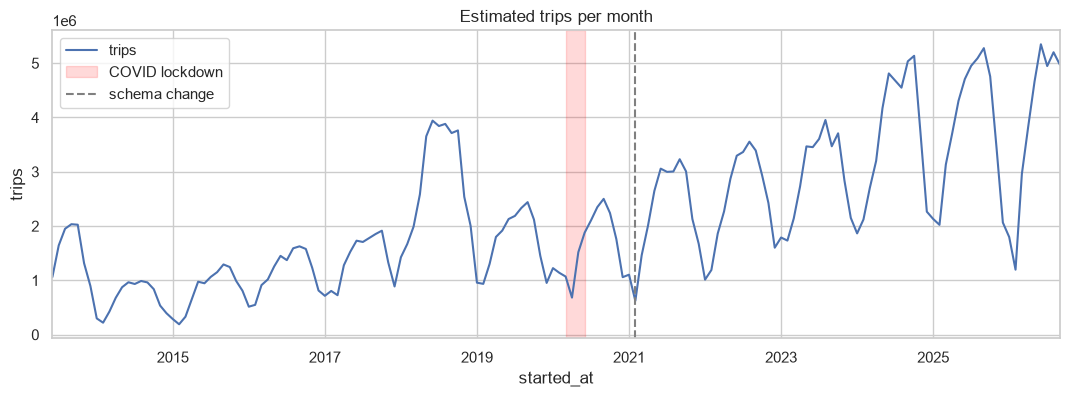

year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
est. trips (millions),10.9,8.1,9.9,13.9,16.3,35.0,20.5,19.5,26.9,29.8,35.0,44.3,45.6,34.9


In [14]:
monthly = (df.set_index("started_at").resample("MS").size() * SCALE).rename("trips")
fig, ax = plt.subplots(figsize=(13, 4))
monthly.plot(ax=ax)
ax.axvspan("2020-03-01", "2020-06-01", color="red", alpha=0.15, label="COVID lockdown")
ax.axvline("2021-02-01", color="grey", ls="--", label="schema change")
ax.set_title("Estimated trips per month"); ax.set_ylabel("trips"); ax.legend(); plt.show()

yearly = df.groupby("year").size() * SCALE
display((yearly / 1e6).round(1).to_frame("est. trips (millions)").T)

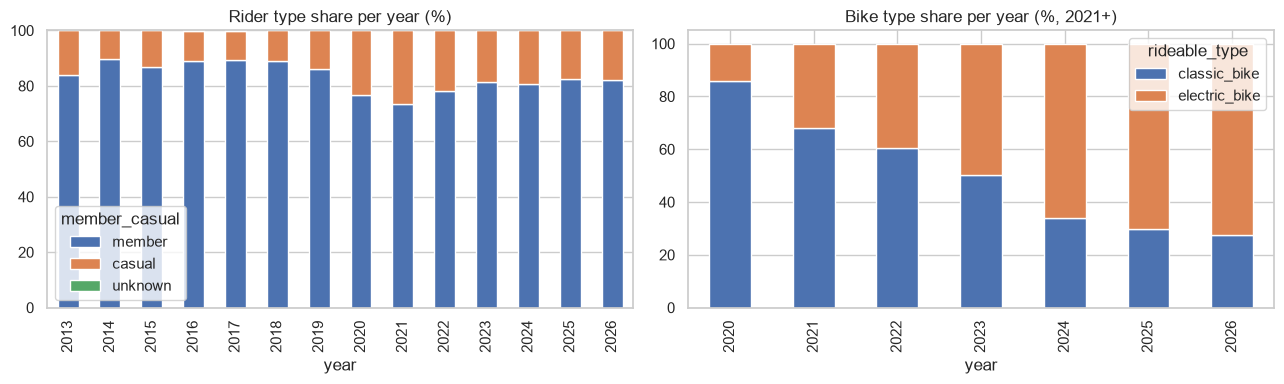

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(pd.crosstab(df["year"], df["member_casual"], normalize="index") * 100).plot(
    kind="bar", stacked=True, ax=ax[0], title="Rider type share per year (%)")
cur = df[df["rideable_type"] != "unknown"]
(pd.crosstab(cur["year"], cur["rideable_type"], normalize="index") * 100).plot(
    kind="bar", stacked=True, ax=ax[1], title="Bike type share per year (%, 2021+)")
plt.tight_layout(); plt.show()

**Write your story here (after running):** e.g. how many times bigger is the system now than in 2014? How deep was the COVID drop, and how fast did it recover? Did casual riders become more important after 2020? How fast did e-bikes grow?

## 9. Station IDs vs station names
To predict demand **per station** over 13 years, we need a station key that stays the same over time. Below we compare the IDs and the names before and after 2021.

In [16]:
legacy = df[df["started_at"] < "2021-02-01"]
current = df[df["started_at"] >= "2021-02-01"]
print("Legacy ID examples :", legacy["start_station_id"].drop_duplicates().head(5).tolist())
print("Current ID examples:", current["start_station_id"].drop_duplicates().head(5).tolist())

last_year = df[df["started_at"] >= df["started_at"].max() - pd.Timedelta(days=365)]
top = last_year.loc[last_year.start_station_name != "no_station", "start_station_name"].value_counts().head(100).index
legacy_names = set(legacy["start_station_name"])
legacy_ids = set(legacy["start_station_id"])
top_ids = last_year[last_year.start_station_name.isin(top)]["start_station_id"].unique()
print(f"Top-100 stations of the last year whose NAME also appears before 2021: {np.mean([n in legacy_names for n in top]):.0%}")
print(f"... whose ID also appears before 2021:                              {np.mean([i in legacy_ids for i in top_ids]):.0%}")

Legacy ID examples : ['402', '83', '358', '403', '285']
Current ID examples: ['5532.01', '7271.01', '7020.09', '5847.06', '7204.08']
Top-100 stations of the last year whose NAME also appears before 2021: 73%
... whose ID also appears before 2021:                              71%


**Conclusion:** the IDs changed format in 2021, so an ID-based key would cut every station's history in two. Most **names** survived, so the model uses the station **name** as its key (`src/features.py`). Stations that were renamed simply start their history at the rename.

## 10. Aggregations
### 10a. Demand per hour, members vs casual, weekday vs weekend

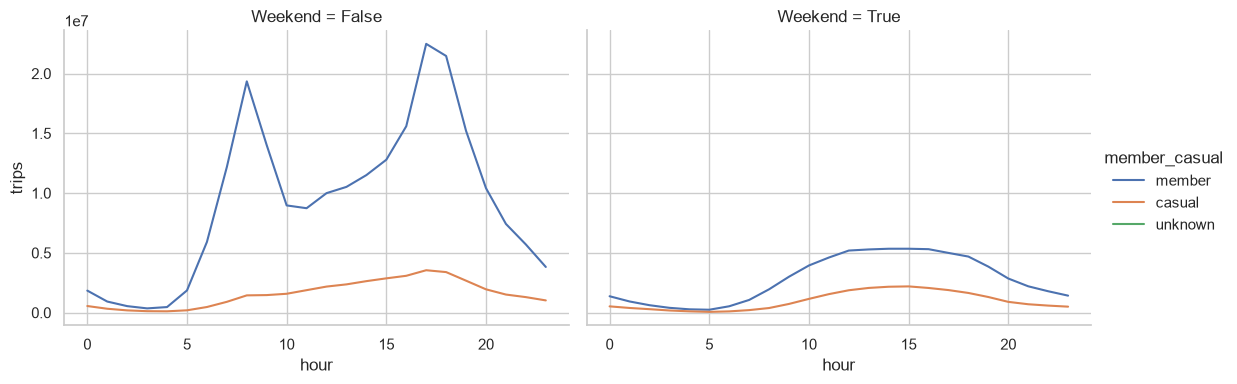

In [17]:
known = df[df["member_casual"] != "unknown"]
hourly = (known.groupby(["hour", "member_casual", "is_weekend"], observed=True).size()
               .mul(SCALE).reset_index(name="trips"))
g = sns.relplot(data=hourly, x="hour", y="trips", hue="member_casual",
                col="is_weekend", kind="line", height=4, aspect=1.4)
g.set_titles("Weekend = {col_name}"); plt.show()

### 10b. Weekday x hour heatmap and seasonality

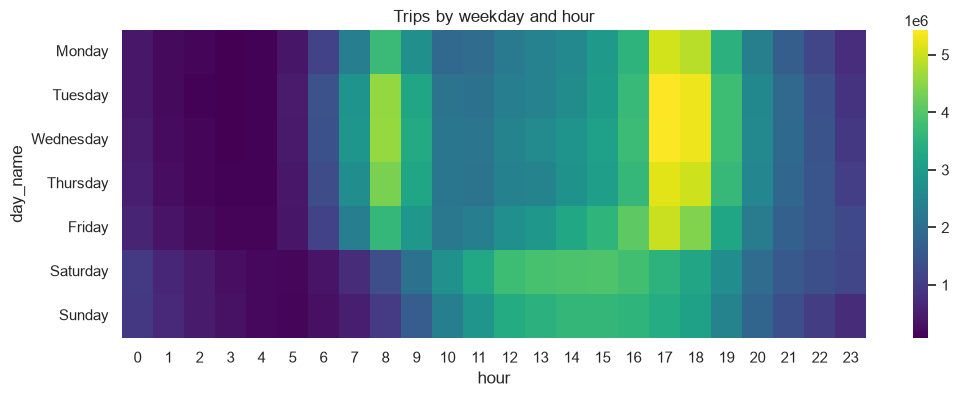

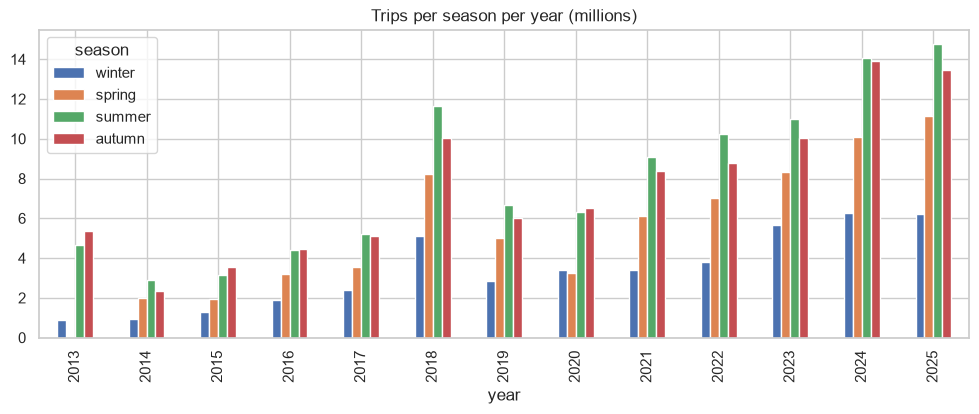

In [18]:
pivot = df.pivot_table(index="day_name", columns="hour", values="duration_min",
                       aggfunc="size", observed=True) * SCALE
plt.figure(figsize=(12, 4)); sns.heatmap(pivot, cmap="viridis"); plt.title("Trips by weekday and hour")
plt.show()

season_year = df[df["year"] < df["year"].max()].pivot_table(
    index="year", columns="season", values="duration_min", aggfunc="size", observed=True) * SCALE
(season_year / 1e6).plot(kind="bar", figsize=(12, 4), title="Trips per season per year (millions)")
plt.show()

### 10c. Duration by rider type and bike type (2021+, when bike type is known)

count  median  mean
member_casual rideable_type                      
member        classic_bike   436985     8.6  12.5
              electric_bike  505385     8.9  12.0
casual        classic_bike   107185    16.3  24.3
              electric_bike  130654    12.6  18.9

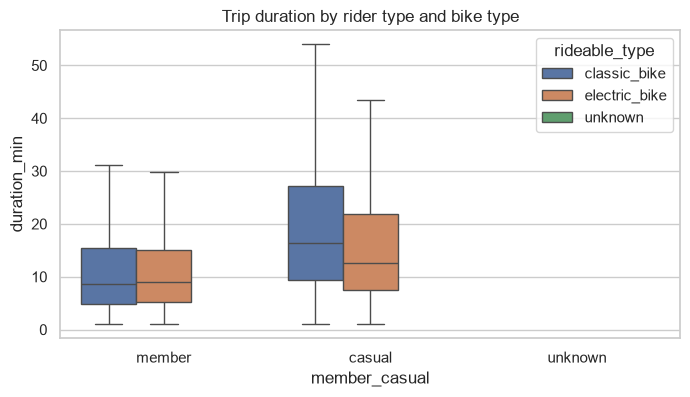

In [19]:
cur = df[(df["rideable_type"] != "unknown") & (df["member_casual"] != "unknown")]
display(cur.groupby(["member_casual", "rideable_type"], observed=True)["duration_min"]
           .agg(["count", "median", "mean"]).round(1))
plt.figure(figsize=(8, 4))
sns.boxplot(data=cur, x="member_casual", y="duration_min", hue="rideable_type", showfliers=False)
plt.title("Trip duration by rider type and bike type"); plt.show()

## 11. Testable hypotheses
Before building a model we check that there is a real pattern to predict. We use alpha = 0.05. Because with ~1.6M rows *everything* becomes significant, we also report an **effect size** and judge on that.

- **H1:** Casual riders take longer trips than members. H0: equal distributions. Mann-Whitney U (duration is very skewed, so no t-test). Effect size: P(casual trip > member trip).
- **H2:** On weekdays, members ride more in rush hours than casual riders do. Chi-square test, effect size Cramer's V.
- **H3 (the one the model relies on):** Hourly demand differs by season and by hour of day. Kruskal-Wallis, effect size epsilon squared. Only the last 12 months are used, so the long-term growth does not distort the comparison.

In [20]:
# H1
mem = known.loc[known.member_casual == "member", "duration_min"]
cas = known.loc[known.member_casual == "casual", "duration_min"]
mem_s = mem.sample(min(200_000, len(mem)), random_state=1)
cas_s = cas.sample(min(200_000, len(cas)), random_state=1)
u, p = stats.mannwhitneyu(cas_s, mem_s, alternative="greater")
print(f"Median duration  casual: {cas.median():.1f} min | member: {mem.median():.1f} min")
print(f"H1: U={u:.3g}, p={p:.3g}, P(casual longer)={u / (len(cas_s) * len(mem_s)):.3f} (0.5 = no effect)")

Median duration  casual: 15.6 min | member: 9.1 min
H1: U=2.73e+10, p=0, P(casual longer)=0.681 (0.5 = no effect)


In [21]:
# H2
wk = known[~known.is_weekend].assign(is_rush=lambda d: d.part_of_day.isin(["morning_rush", "evening_rush"]))
ct = pd.crosstab(wk["member_casual"].astype(str), wk["is_rush"])
display(ct)
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"H2: chi2={chi2:.3g}, p={p:.3g}, Cramer's V={np.sqrt(chi2 / ct.values.sum()):.3f}")
print(wk.groupby("member_casual", observed=True)["is_rush"].mean().round(3))

is_rush,False,True
member_casual,,
casual,103951,84922
member,479296,630905


H2: chi2=9.19e+03, p=0, Cramer's V=0.084
member_casual
member    0.568
casual    0.450
Name: is_rush, dtype: float64


In [22]:
# H3
recent = df[df["started_at"] >= df["started_at"].max() - pd.Timedelta(days=365)]
counts = recent.groupby(["date", "hour", "season"], observed=True).size().reset_index(name="trips")
for factor in ["season", "hour"]:
    groups = [g["trips"].values for _, g in counts.groupby(factor, observed=True)]
    h, p = stats.kruskal(*groups)
    eps2 = (h - len(groups) + 1) / (len(counts) - len(groups))
    print(f"H3 {factor:6s}: H={h:.3g}, p={p:.3g}, epsilon^2={eps2:.3f}")
display(counts.groupby("season", observed=True)["trips"].median().mul(SCALE).to_frame("median trips/hour (system-wide)"))

H3 season: H=1.12e+03, p=7.81e-243, epsilon^2=0.133
H3 hour  : H=4.66e+03, p=0, epsilon^2=0.551


,median trips/hour (system-wide)
season,
winter,2000.0
spring,4600.0
summer,6800.0
autumn,5400.0


**Conclusions (rewrite in your own words after running):**
- H1: ... accept/reject? How large is the effect?
- H2: ...
- H3: ...

**What this means for the model:** demand has a strong daily rhythm, a weekday/weekend difference, seasonality and long-term growth. So we predict **hourly demand per station**, with hour, weekday, month, holiday and year as features, and the station *name* as the key.

Next: `03_prepare` runs exactly these cleaning steps on **all** trips.